# Praktikum Web Crawling, Graph, dan PageRank

Notebook ini mengubah alur utama proyek Flask crawler menjadi pembelajaran yang dapat dijalankan bertahap di Jupyter Notebook.

**Yang akan dipelajari**
1. Mengambil halaman web dan mengekstrak hyperlink.
2. Melakukan crawling menggunakan antrean (*Breadth-First Search/BFS*) berdasarkan `depth`.
3. Membangun graf berarah: node = URL, edge = tautan dari satu URL ke URL lain.
4. Menghitung *in-degree* dan PageRank.
5. Menampilkan tabel URL hasil crawl, seluruh node graf, dan graf interaktif yang node-nya dapat diklik.

> Jalankan cell dari atas ke bawah. Crawling mengakses situs sungguhan, sehingga gunakan situs yang mengizinkan akses otomatis, periksa `robots.txt`/ketentuan situs, batasi jumlah halaman, dan beri jeda permintaan. Hasil jaringan dapat berbeda dari satu waktu ke waktu lain.

## 1. Instalasi pustaka

Cell ini memasang pustaka yang digunakan. `requests` mengambil halaman, `BeautifulSoup` membaca HTML, `networkx` mengelola graf dan PageRank, `pandas` membuat tabel, sedangkan `pyvis` menampilkan graf interaktif.

In [28]:
%pip install requests beautifulsoup4 networkx pandas pyvis matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import pustaka

Kita mengimpor modul untuk HTTP, parsing HTML, normalisasi URL, pengelolaan antrean, analisis graf, tabel, dan visualisasi.

In [29]:
import time
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from collections import deque
from urllib.parse import urljoin, urlparse
from IPython.display import display, HTML

try:
    from pyvis.network import Network
    PYVIS_AVAILABLE = True
except ImportError:
    PYVIS_AVAILABLE = False

print("Pustaka siap digunakan.")

Pustaka siap digunakan.


## 3. Konfigurasi crawling

Ubah nilai di bawah sebelum menjalankan crawling.

- `START_URL`: halaman awal.
- `MAX_DEPTH`: kedalaman maksimum. Halaman awal berada pada depth 0; tautannya depth 1; tautan dari depth 1 berada pada depth 2.
- `MAX_PAGES`: batas jumlah URL yang diproses (termasuk permintaan yang gagal).
- `DELAY`: jeda antarpermintaan dalam detik.
- `SAME_DOMAIN_ONLY`: `False` mengizinkan tautan ke domain lain, seperti konfigurasi pemanggilan crawler pada aplikasi Flask yang diberikan.

**Catatan:** membatasi domain ke `False` dapat memperluas crawl dengan sangat cepat. Mulailah dari `MAX_PAGES` kecil.

In [30]:
START_URL = "https://www2.trunojoyo.ac.id"
MAX_DEPTH = 3
MAX_PAGES = 50
REQUEST_TIMEOUT = 10
DELAY = 0.5
SAME_DOMAIN_ONLY = False
VERIFY_SSL = True

# Tambahkan slash bila URL hanya berupa domain.
if not START_URL.startswith(("http://", "https://")):
    START_URL = "https://" + START_URL

print({
    "start_url": START_URL,
    "max_depth": MAX_DEPTH,
    "max_pages": MAX_PAGES,
    "same_domain_only": SAME_DOMAIN_ONLY
})

{'start_url': 'https://www2.trunojoyo.ac.id', 'max_depth': 3, 'max_pages': 50, 'same_domain_only': False}


## 4. Fungsi normalisasi URL

URL yang ditemukan pada atribut `href` dapat berupa URL relatif, misalnya `/profil`, atau URL absolut. `urljoin()` mengubahnya menjadi URL absolut.

Fragmen setelah `#` dihapus agar URL seperti `https://site.test/page#bagian-a` dan `https://site.test/page#bagian-b` dianggap sebagai halaman yang sama. Query string (`?id=...`) tetap dipertahankan, mengikuti logika proyek.

**Rumus/aturan normalisasi:**

\[
U_{normal} = scheme + "://" + netloc + path + ("?" + query)
\]

Dengan demikian, URL yang sama setelah normalisasi hanya dimasukkan sekali ke antrean crawl.

In [31]:
def normalize_url(url, base_url):
    full_url = urljoin(base_url, url)
    parsed = urlparse(full_url)

    if parsed.scheme not in ("http", "https") or not parsed.netloc:
        return None

    normalized = f"{parsed.scheme}://{parsed.netloc}{parsed.path}"
    if parsed.query:
        normalized += f"?{parsed.query}"

    return normalized


# Contoh
contoh = normalize_url("/artikel#komentar", "https://example.com")
print(contoh)

https://example.com/artikel


## 5. Mengambil halaman dan mengekstrak link

`fetch_page()` meminta HTML dari server. Jika status HTTP gagal atau terjadi masalah koneksi, fungsi mengembalikan `None`.

`extract_links()` mengambil semua elemen `<a>` yang memiliki atribut `href`, kemudian menormalisasi URL. Duplikasi akan dihilangkan dengan `set` pada tahap berikutnya.

In [32]:
HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (compatible; EducationalWebCrawler/1.0)"
    )
}

errors = []

def fetch_page(url):
    try:
        response = requests.get(
            url,
            headers=HEADERS,
            timeout=REQUEST_TIMEOUT,
            verify=VERIFY_SSL,
            allow_redirects=True
        )
        response.raise_for_status()
        return response.text, response.url
    except requests.RequestException as exc:
        errors.append({"url": url, "error": str(exc)})
        return None, None


def extract_links(html, base_url):
    soup = BeautifulSoup(html, "html.parser")
    links = set()

    for tag in soup.find_all("a", href=True):
        normalized = normalize_url(tag["href"], base_url)
        if normalized:
            links.add(normalized)

    return sorted(links)

print("Fungsi fetch_page() dan extract_links() telah dibuat.")

Fungsi fetch_page() dan extract_links() telah dibuat.


## 6. Algoritma crawling (BFS)

Crawling menggunakan antrean FIFO (*First In, First Out*), sehingga halaman diproses berdasarkan urutan kedalaman.

**Alur:**
1. Masukkan URL awal ke antrean dengan depth 0.
2. Ambil URL paling depan.
3. Jika belum pernah diproses, ambil HTML.
4. Tambahkan URL yang berhasil diambil sebagai node.
5. Untuk setiap hyperlink, tambahkan edge `URL saat ini → URL tujuan`.
6. Masukkan URL tujuan ke antrean jika belum pernah dikunjungi/diantrekan dan depth masih memungkinkan.

**Pseudocode:**

```text
queue = [(start_url, 0)]
while queue tidak kosong dan jumlah diproses < MAX_PAGES:
    url, depth = queue.pop(0)
    ambil halaman
    untuk setiap link:
        tambahkan edge(url, link)
        jika depth < MAX_DEPTH dan link belum diproses/diantrekan:
            queue.append((link, depth + 1))
```

**Penting membedakan dua daftar:**
- `crawled_urls`: URL yang berhasil diambil HTML-nya, urut sesuai proses crawl.
- `graph.nodes`: seluruh URL yang muncul sebagai node, termasuk URL tujuan tautan yang belum sempat di-crawl karena batas depth, batas halaman, atau kegagalan request.

Batas `MAX_PAGES` pada kode ini menghitung URL yang telah diproses, termasuk request gagal, serupa dengan `visited` pada proyek.

In [33]:
def crawl_website(
    start_url,
    max_depth=2,
    max_pages=20,
    delay=0.5,
    same_domain_only=False
):
    graph = nx.DiGraph()
    queue = deque([(start_url, 0)])
    queued = {start_url}
    visited = set()
    crawled_urls = []
    crawl_log = []

    start_host = urlparse(start_url).netloc.lower()

    while queue and len(visited) < max_pages:
        requested_url, depth = queue.popleft()

        if depth > max_depth or requested_url in visited:
            continue

        html, final_url = fetch_page(requested_url)

        if html is None or final_url is None:
            visited.add(requested_url)
            crawl_log.append({
                "url": requested_url,
                "depth": depth,
                "status": "Gagal"
            })
            continue

        current_url = normalize_url(final_url, final_url)

        if current_url is None or current_url in visited:
            continue

        visited.add(current_url)
        crawled_urls.append(current_url)
        graph.add_node(current_url)

        links = extract_links(html, final_url)

        for link in links:
            parsed = urlparse(link)

            if same_domain_only and parsed.netloc.lower() != start_host:
                continue

            if link == current_url:
                continue

            # Edge dibuat meskipun URL tujuan belum berhasil di-crawl.
            graph.add_edge(current_url, link)

            # queued mencegah URL yang sama masuk antrean lebih dari sekali.
            if (
                link not in visited
                and link not in queued
                and depth < max_depth
                and len(visited) + len(queue) < max_pages
            ):
                queue.append((link, depth + 1))
                queued.add(link)

        crawl_log.append({
            "url": current_url,
            "depth": depth,
            "status": "Berhasil di-crawl"
        })

        print(
            f"[{len(visited)}/{max_pages}] "
            f"Depth {depth}: {current_url} | "
            f"Node: {graph.number_of_nodes()} | Edge: {graph.number_of_edges()}"
        )

        if delay:
            time.sleep(delay)

    return {
        "graph": graph,
        "crawled_urls": crawled_urls,
        "crawl_log": crawl_log,
        "visited": visited
    }

print("Fungsi crawling siap.")

Fungsi crawling siap.


## 7. Jalankan crawling

Cell ini menjalankan proses pengambilan halaman sesuai konfigurasi. Waktu proses bergantung pada jumlah halaman, kecepatan server, dan jeda permintaan.

Jika ingin mengulang dari awal, jalankan cell ini lagi. Daftar `errors` juga dapat diperiksa pada bagian hasil.

In [34]:
errors.clear()

crawl_result = crawl_website(
    start_url=START_URL,
    max_depth=MAX_DEPTH,
    max_pages=MAX_PAGES,
    delay=DELAY,
    same_domain_only=SAME_DOMAIN_ONLY
)

G = crawl_result["graph"]
crawled_urls = crawl_result["crawled_urls"]

print("\nCrawling selesai.")
print("Berhasil di-crawl:", len(crawled_urls))
print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())
print("Jumlah error:", len(errors))

[1/50] Depth 0: https://www2.trunojoyo.ac.id/ | Node: 64 | Edge: 63
[4/50] Depth 1: https://drive.google.com/drive/folders/1G8tmMYJ6S58BtzwRP9V_78XkNOl3aR8y?usp=sharing | Node: 69 | Edge: 68
[9/50] Depth 1: https://fk.trunojoyo.ac.id/ | Node: 100 | Edge: 101
[11/50] Depth 1: https://karir.trunojoyo.ac.id/ | Node: 147 | Edge: 148
[12/50] Depth 1: https://kemdiktisaintek.go.id/ | Node: 193 | Edge: 194
[14/50] Depth 1: https://library.trunojoyo.ac.id/ | Node: 200 | Edge: 201
[16/50] Depth 1: https://lppm.trunojoyo.ac.id/ | Node: 229 | Edge: 231
[17/50] Depth 1: https://pasca.trunojoyo.ac.id/ | Node: 258 | Edge: 261
[19/50] Depth 1: https://pmb.trunojoyo.ac.id/ | Node: 268 | Edge: 284
[20/50] Depth 1: https://pmb.trunojoyo.ac.id/2026/04/kesempatan-daftar-ulang-snbp-utm-2026/ | Node: 270 | Edge: 302
[21/50] Depth 1: https://pmb.trunojoyo.ac.id/2026/05/announcement-of-accepted-recipients-for-universitas-trunojoyo-madura-international-students-scholarship-2026/ | Node: 273 | Edge: 321
[22/50]

## 8. Tabel seluruh URL yang berhasil di-crawl

Tabel ini menunjukkan halaman yang benar-benar berhasil diambil HTML-nya. Urutan tabel mengikuti urutan BFS saat crawling.

`Depth` adalah jarak langkah dari halaman awal. Halaman awal memiliki depth 0.

In [35]:
crawl_df = pd.DataFrame(crawl_result["crawl_log"])
display(crawl_df if not crawl_df.empty else pd.DataFrame(
    columns=["url", "depth", "status"]
))

,url,depth,status
0,https://www2.trunojoyo.ac.id/,0,Berhasil di-crawl
1,https://asrama.trunojoyo.ac.id/,1,Gagal
2,https://bima.kemdiktisaintek.go.id/,1,Gagal
3,https://drive.google.com/drive/folders/1G8tmMY...,1,Berhasil di-crawl
4,https://feb.trunojoyo.ac.id/,1,Gagal
5,https://fik.trunojoyo.ac.id/,1,Gagal
6,https://fip.trunojoyo.ac.id/,1,Gagal
7,https://fisib.trunojoyo.ac.id/,1,Gagal
8,https://fk.trunojoyo.ac.id/,1,Berhasil di-crawl
9,https://hukum.trunojoyo.ac.id/,1,Gagal


## 9. Tabel seluruh URL yang menjadi node graf

Tabel ini berbeda dari tabel crawl. Setiap URL yang menjadi sumber atau tujuan edge akan menjadi node dalam `DiGraph`. Karena itu, sebuah URL bisa muncul di tabel node meskipun belum berhasil diambil HTML-nya.

- `In-degree`: jumlah edge yang masuk ke node.
- `Out-degree`: jumlah edge yang keluar dari node.

Rumus derajat masuk:

\[
deg^{-}(v) = |\{u : (u,v) \in E\}|
\]

Rumus derajat keluar:

\[
deg^{+}(v) = |\{w : (v,w) \in E\}|
\]

In [36]:
node_rows = []
for node in G.nodes():
    node_rows.append({
        "URL": node,
        "In-degree": G.in_degree(node),
        "Out-degree": G.out_degree(node),
        "Berhasil di-crawl": node in set(crawled_urls)
    })

nodes_df = pd.DataFrame(node_rows)
if not nodes_df.empty:
    nodes_df = nodes_df.sort_values(
        ["In-degree", "Out-degree"],
        ascending=False
    ).reset_index(drop=True)

display(nodes_df if not nodes_df.empty else pd.DataFrame(
    columns=["URL", "In-degree", "Out-degree", "Berhasil di-crawl"]
))

,URL,In-degree,Out-degree,Berhasil di-crawl
0,https://pmb.trunojoyo.ac.id/seleksi-nasional-b...,23,25,True
1,https://pmb.trunojoyo.ac.id/,23,23,True
2,https://pmb.trunojoyo.ac.id/seleksi-nasional-b...,23,20,True
3,https://pmb.trunojoyo.ac.id/seleksi-mandiri-ma...,23,18,True
4,https://pmb.trunojoyo.ac.id/universitas-trunod...,23,17,True
...,...,...,...,...
715,https://www2.trunojoyo.ac.id/syukuri-dies-nata...,1,0,False
716,https://www2.trunojoyo.ac.id/utm-lantik-empat-...,1,0,False
717,https://www2.trunojoyo.ac.id/utm-perkuat-komit...,1,0,False
718,https://www2.trunojoyo.ac.id/utm-tembus-the-wo...,1,0,False


## 10. Menghitung PageRank

PageRank mengukur kepentingan relatif sebuah node berdasarkan tautan yang mengarah kepadanya. Node yang menerima tautan dari node penting dapat memperoleh skor lebih besar.

Rumus iteratif PageRank:

\[
PR(v) = \frac{1-d}{N}
+ d \sum_{u \in In(v)} \frac{PR(u)}{L(u)}
\]

Keterangan:
- \(PR(v)\): skor PageRank node \(v\).
- \(d\): *damping factor*, pada praktik umum sering digunakan 0,85.
- \(N\): jumlah node dalam graf.
- \(In(v)\): himpunan node yang memiliki edge menuju \(v\).
- \(L(u)\): jumlah tautan keluar (*out-degree*) dari node \(u\).

NetworkX menghitung nilai iteratif hingga konvergen atau mencapai batas iterasi. Skor PageRank bukan sekadar jumlah link masuk; jumlah link masuk adalah *in-degree*.

In [37]:
DAMPING_FACTOR = 0.85
MAX_ITERATIONS = 100
TOLERANCE = 1.0e-6

if G.number_of_nodes() > 0:
    pagerank_scores = nx.pagerank(
        G,
        alpha=DAMPING_FACTOR,
        max_iter=MAX_ITERATIONS,
        tol=TOLERANCE
    )
else:
    pagerank_scores = {}

print("Jumlah skor PageRank:", len(pagerank_scores))
print("Total skor PageRank:", sum(pagerank_scores.values()))

Jumlah skor PageRank: 720
Total skor PageRank: 1.0000000000000002


## 11. Tabel ranking: In-degree dan PageRank

Pada aplikasi web proyek, urutan tabel ranking diurutkan berdasarkan **In-degree terbesar**, lalu PageRank sebagai pemecah nilai yang sama. Cell ini mengikuti aturan tersebut.

Rumus pengurutan:
1. `In-degree` menurun.
2. Jika sama, `PageRank` menurun.

Jadi, kolom PageRank ditampilkan sebagai skor analisis, tetapi bukan kriteria utama urutan tabel ini.

In [38]:
ranking_rows = []
for node in G.nodes():
    ranking_rows.append({
        "URL": node,
        "In-degree": G.in_degree(node),
        "PageRank": pagerank_scores.get(node, 0.0)
    })

ranking_df = pd.DataFrame(ranking_rows)
if not ranking_df.empty:
    ranking_df = ranking_df.sort_values(
        ["In-degree", "PageRank"],
        ascending=[False, False]
    ).reset_index(drop=True)
    ranking_df.insert(0, "Rank", range(1, len(ranking_df) + 1))

display(ranking_df if not ranking_df.empty else pd.DataFrame(
    columns=["Rank", "URL", "In-degree", "PageRank"]
))

,Rank,URL,In-degree,PageRank
0,1,https://pmb.trunojoyo.ac.id/seleksi-nasional-b...,23,0.002730
1,2,https://pmb.trunojoyo.ac.id/,23,0.002722
2,3,https://pmb.trunojoyo.ac.id/seleksi-nasional-b...,23,0.002708
3,4,https://pmb.trunojoyo.ac.id/seleksi-mandiri-ma...,23,0.002696
4,5,https://pmb.trunojoyo.ac.id/universitas-trunod...,23,0.002688
...,...,...,...,...
715,716,https://www2.trunojoyo.ac.id/syukuri-dies-nata...,1,0.001323
716,717,https://www2.trunojoyo.ac.id/utm-lantik-empat-...,1,0.001323
717,718,https://www2.trunojoyo.ac.id/utm-perkuat-komit...,1,0.001323
718,719,https://www2.trunojoyo.ac.id/utm-tembus-the-wo...,1,0.001323


## 12. Visualisasi graf interaktif

Graf berarah memperlihatkan hubungan hyperlink:
- Node adalah URL.
- Panah `A → B` berarti halaman A memiliki tautan menuju halaman B.
- Ukuran node dibuat lebih besar untuk 10 node dengan In-degree tertinggi.
- Warna emas menandai 10 node tersebut.
- Klik node untuk menyorot node tersebut dan tetangga langsungnya. Tombol tampilkan semua mengembalikan seluruh graf.

`pyvis` menampilkan visualisasi HTML interaktif langsung di notebook.

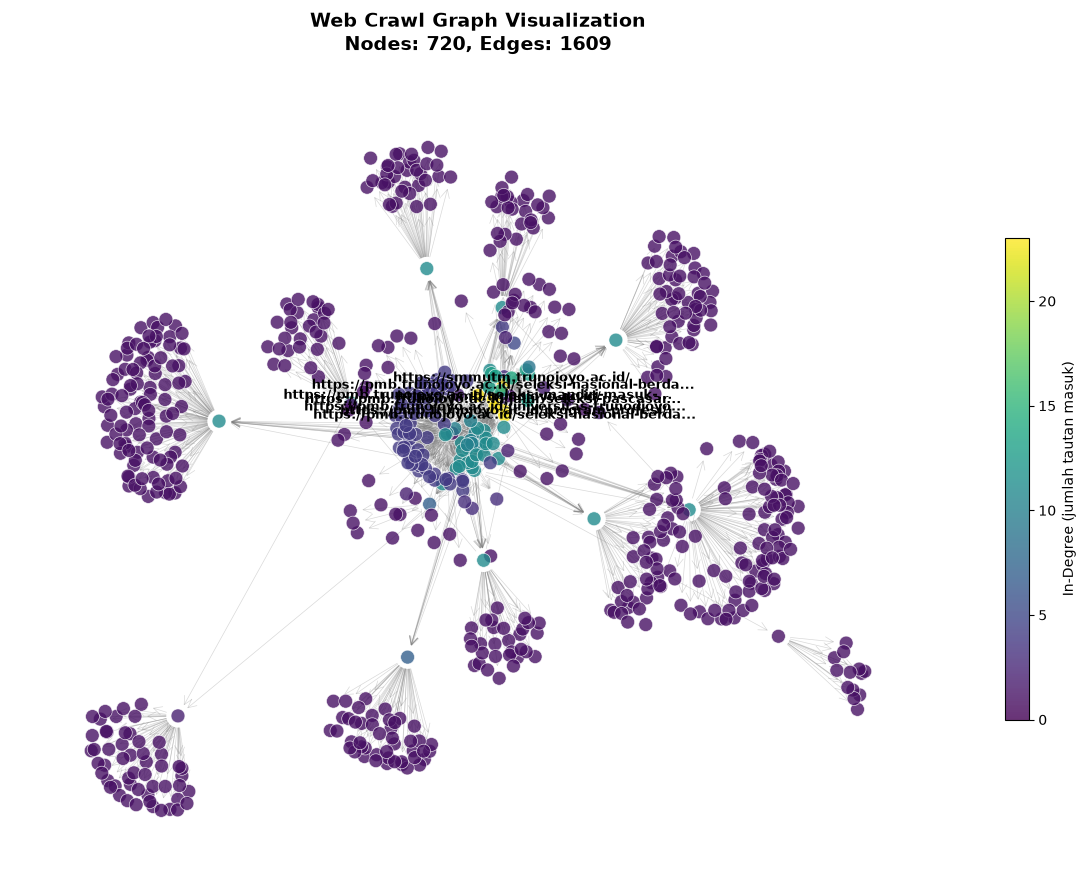

In [39]:

def visualize_graph(
    graph,
    pagerank_scores,
    top_n_labels=8,
    figsize=(12, 9),
    node_size_factor=3000,
    layout_seed=42
):
    """
    Visualisasi graf web:
    - Ukuran node berdasarkan PageRank.
    - Warna node berdasarkan In-degree.
    - Label ditampilkan pada node dengan PageRank tertinggi.
    """

    if graph.number_of_nodes() == 0:
        print("Graph is empty, nothing to visualize.")
        return

    # Mengurutkan node berdasarkan PageRank tertinggi
    sorted_nodes = sorted(
        pagerank_scores.items(),
        key=lambda item: item[1],
        reverse=True
    )

    top_nodes = [
        node for node, _ in sorted_nodes[:top_n_labels]
    ]

    # Ukuran node berdasarkan PageRank
    node_sizes = [
        max(
            100,
            pagerank_scores.get(node, 0) * node_size_factor
        )
        for node in graph.nodes()
    ]

    # Warna node berdasarkan In-degree
    in_degrees = dict(graph.in_degree())

    max_in_degree = max(
        in_degrees.values(),
        default=0
    )

    node_colors = [
        in_degrees.get(node, 0)
        for node in graph.nodes()
    ]

    # Mengatur posisi node menggunakan Spring Layout
    pos = nx.spring_layout(
        graph,
        seed=layout_seed,
        k=2 / max(1, graph.number_of_nodes() ** 0.5),
        iterations=50
    )

    # Membuat area visualisasi
    fig, ax = plt.subplots(figsize=figsize)

    # Menggambar edge atau hubungan antar-node
    nx.draw_networkx_edges(
        graph,
        pos,
        ax=ax,
        alpha=0.3,
        edge_color="gray",
        arrows=True,
        arrowsize=15,
        arrowstyle="->",
        width=0.5
    )

    # Menggambar node
    nodes = nx.draw_networkx_nodes(
        graph,
        pos,
        ax=ax,
        node_size=node_sizes,
        node_color=node_colors,
        cmap=plt.cm.viridis,
        vmin=0,
        vmax=max(1, max_in_degree),
        alpha=0.8,
        edgecolors="white",
        linewidths=0.5
    )

    # Label hanya untuk node dengan PageRank tertinggi
    labels = {
        node: (
            node[:50] + "..."
            if len(node) > 50 else node
        )
        for node in top_nodes
        if node in graph
    }

    nx.draw_networkx_labels(
        graph,
        pos,
        labels=labels,
        ax=ax,
        font_size=9,
        font_weight="bold"
    )

    # Colorbar untuk menunjukkan In-degree
    colorbar = fig.colorbar(
        nodes,
        ax=ax,
        shrink=0.6,
        aspect=20
    )

    colorbar.set_label(
        "In-Degree (jumlah tautan masuk)"
    )

    # Judul visualisasi
    ax.set_title(
        f"Web Crawl Graph Visualization\n"
        f"Nodes: {graph.number_of_nodes()}, "
        f"Edges: {graph.number_of_edges()}",
        fontsize=14,
        fontweight="bold",
        pad=20
    )

    ax.axis("off")
    fig.tight_layout()
    plt.show()


# Menampilkan graph hasil crawling
visualize_graph(
    G,
    pagerank_scores,
    top_n_labels=8,
    figsize=(12, 9)
)


## 13. Ringkasan statistik graf

Kepadatan (*density*) graf berarah tanpa self-loop dihitung dengan:

\[
D = \frac{|E|}{|V|(|V|-1)}
\]

dengan \(|V|\) jumlah node dan \(|E|\) jumlah edge. Nilainya berada pada rentang 0 sampai 1 untuk graf sederhana berarah tanpa self-loop.

In [40]:
stats = {
    "Jumlah node": G.number_of_nodes(),
    "Jumlah edge": G.number_of_edges(),
    "Halaman berhasil di-crawl": len(crawled_urls),
    "Jumlah error request": len(errors),
    "Density": nx.density(G) if G.number_of_nodes() > 1 else 0.0,
    "Rata-rata in-degree": (
        sum(dict(G.in_degree()).values()) / G.number_of_nodes()
        if G.number_of_nodes() else 0
    ),
    "Rata-rata out-degree": (
        sum(dict(G.out_degree()).values()) / G.number_of_nodes()
        if G.number_of_nodes() else 0
    )
}

display(pd.DataFrame(
    [{"Metrik": key, "Nilai": value} for key, value in stats.items()]
))

,Metrik,Nilai
0,Jumlah node,720.000000
1,Jumlah edge,1609.000000
2,Halaman berhasil di-crawl,37.000000
3,Jumlah error request,13.000000
4,Density,0.003108
5,Rata-rata in-degree,2.234722
6,Rata-rata out-degree,2.234722


## 14. Periksa error crawling

Request dapat gagal karena timeout, DNS, pembatasan server, SSL, atau status HTTP. Kegagalan request tidak selalu berarti kode crawler salah.

In [41]:
errors_df = pd.DataFrame(errors)
display(errors_df if not errors_df.empty else pd.DataFrame(
    columns=["url", "error"]
))

,url,error
0,https://asrama.trunojoyo.ac.id/,HTTPSConnectionPool(host='asrama.trunojoyo.ac....
1,https://bima.kemdiktisaintek.go.id/,HTTPSConnectionPool(host='bima.kemdiktisaintek...
2,https://feb.trunojoyo.ac.id/,HTTPSConnectionPool(host='feb.trunojoyo.ac.id'...
3,https://fik.trunojoyo.ac.id/,HTTPSConnectionPool(host='fik.trunojoyo.ac.id'...
4,https://fip.trunojoyo.ac.id/,HTTPSConnectionPool(host='fip.trunojoyo.ac.id'...
5,https://fisib.trunojoyo.ac.id/,HTTPSConnectionPool(host='fisib.trunojoyo.ac.i...
6,https://hukum.trunojoyo.ac.id/,HTTPSConnectionPool(host='hukum.trunojoyo.ac.i...
7,https://labterpadu.trunojoyo.ac.id/,HTTPSConnectionPool(host='labterpadu.trunojoyo...
8,https://lpmpp.trunojoyo.ac.id/,HTTPSConnectionPool(host='lpmpp.trunojoyo.ac.i...
9,https://pertanian.trunojoyo.ac.id/,HTTPSConnectionPool(host='pertanian.trunojoyo....


## 15. Simpan hasil ke file

Cell ini menyimpan:
- `crawl_history.csv`: urutan URL yang diproses beserta status dan depth.
- `all_graph_nodes.csv`: seluruh node dan derajatnya.
- `pagerank_ranking.csv`: ranking In-degree dan skor PageRank.
- `crawler_graph.graphml`: graf berarah agar dapat dibuka kembali dengan NetworkX atau perangkat lunak analisis graf.

File akan disimpan di direktori kerja notebook.

In [42]:
crawl_df.to_csv("crawl_history.csv", index=False, encoding="utf-8-sig")
nodes_df.to_csv("all_graph_nodes.csv", index=False, encoding="utf-8-sig")
ranking_df.to_csv("pagerank_ranking.csv", index=False, encoding="utf-8-sig")
nx.write_graphml(G, "crawler_graph.graphml")

print("File hasil berhasil disimpan di direktori kerja notebook.")

File hasil berhasil disimpan di direktori kerja notebook.
